# Train the rocket controller offline

The idea here is to train the model based on the expert data. You can use all the data or not. There may be some benefit from not using all of the data.

Use this file as both training and data analysis to make your informed changes.

I expect extra plots/records of runs; If you submit this file unchanged you will only be able to receive a maximum score of 1 out of 2.


In [76]:
# DO NOT REMOVE THESE
# These two lines make sure any changes you make in scaffold.py
# are automatically reloaded each time you run a cell in this notebook.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scaffold import Controller

landings_path = "landings.csv"
weights_path = "weights.npz"

# You will need to tune these to get a good model.
learning_rate = 0.01
epochs = 2000

In [78]:
landings = pd.read_csv(landings_path)
print(f"Loaded {len(landings)} landings from {landings_path}")

# IS THIS A CORRECT SPLIT? - it also may not be the most efficient way to do it.
train_landings = landings.sample(frac=0.8, random_state=42)
val_landings = landings.drop(train_landings.index).sample(frac=0.5, random_state=42)
test_landings = landings.drop(train_landings.index).drop(val_landings.index)
print(f"Training set: {len(train_landings)} landings, Validation set: {len(val_landings)} landings, Test set: {len(test_landings)} landings")

Loaded 130008 landings from landings.csv
Training set: 104006 landings, Validation set: 13001 landings, Test set: 13001 landings


In [79]:
display(train_landings.head(5))
print("Descriptive statistics for the train_landings dataset:")
numerical_features = ["x", "y",  "vx", "vy", "theta", "omega", "fuel_mass", "actual_thrust", "actual_gimbal", "wind_x", "wind_y", "air_density"]
display(train_landings[numerical_features].describe())

,run_id,step,x,y,vx,vy,theta,omega,fuel_mass,actual_thrust,actual_gimbal,wind_x,wind_y,air_density,action,success
129434,995,97,0.480101,26.401239,1.986252,-8.915606,0.004498,0.024793,1903.432583,525560.0,0.000000,4.254497,-0.657291,1.221201,2,0
23367,180,21,-0.312382,400.885726,-0.223833,-64.943839,0.028267,-0.004723,9074.090613,525560.0,0.000000,0.852415,1.992491,1.168567,2,1
69194,533,13,-40.477645,593.863381,4.300671,-66.598923,-0.064885,0.073717,9136.694386,0.0,0.000000,-5.638318,-0.758433,1.142335,0,1
70737,544,24,6.867950,330.925174,-1.145869,-57.877182,-0.012775,0.000275,9672.927727,525560.0,0.000000,-0.351800,-1.247093,1.178224,2,1
115686,888,12,-16.805427,291.601794,-7.964767,-60.718596,0.088921,-0.089491,4709.599130,681650.0,-0.087266,5.531487,-1.272994,1.183688,3,0


Descriptive statistics for the train_landings dataset:


,x,y,vx,vy,theta,omega,fuel_mass,actual_thrust,actual_gimbal,wind_x,wind_y,air_density
count,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000,104006.000000
mean,0.371797,186.846429,0.040434,-36.737798,0.001858,-0.000378,7328.895750,476914.093033,-0.000169,0.110250,-0.029403,1.198562
std,22.507826,154.194764,2.431930,20.692960,0.046447,0.017865,2182.096404,205758.348840,0.025982,4.107308,1.153001,0.021589
min,-102.309498,18.660389,-11.398096,-86.727180,-0.216272,-0.101063,81.697497,0.000000,-0.087266,-6.995978,-1.999217,1.128234
25%,-8.309732,48.915196,-1.060043,-54.431027,-0.021776,-0.009474,6224.334102,525560.000000,0.000000,-3.638878,-1.003461,1.182726
50%,-0.100553,143.059206,0.024686,-38.458497,0.000636,-0.000126,7709.965549,525560.000000,0.000000,0.458071,-0.093778,1.204555
75%,9.222137,298.508496,1.111435,-19.160448,0.023859,0.008819,8833.431596,525560.000000,0.000000,3.676479,0.958981,1.217971
max,106.027507,699.441784,9.772648,2.812550,0.199501,0.132865,11971.113066,845000.000000,0.087266,6.988351,1.992491,1.222314


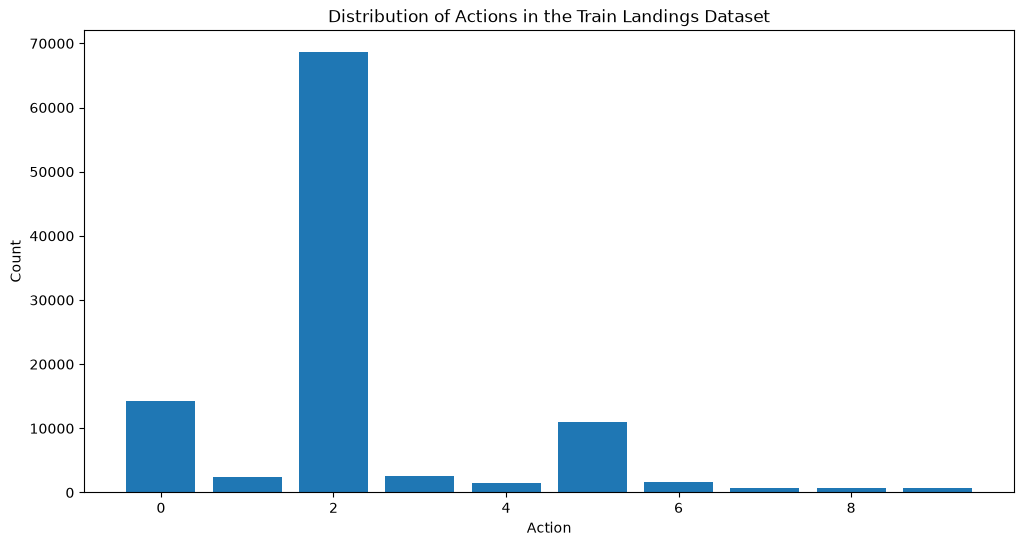

In [80]:
plt.figure(figsize=(12, 6))
plt.bar(train_landings["action"].value_counts().index, train_landings["action"].value_counts().values)
plt.title("Distribution of Actions in the Train Landings Dataset")
plt.xlabel("Action")
plt.ylabel("Count")
plt.show()

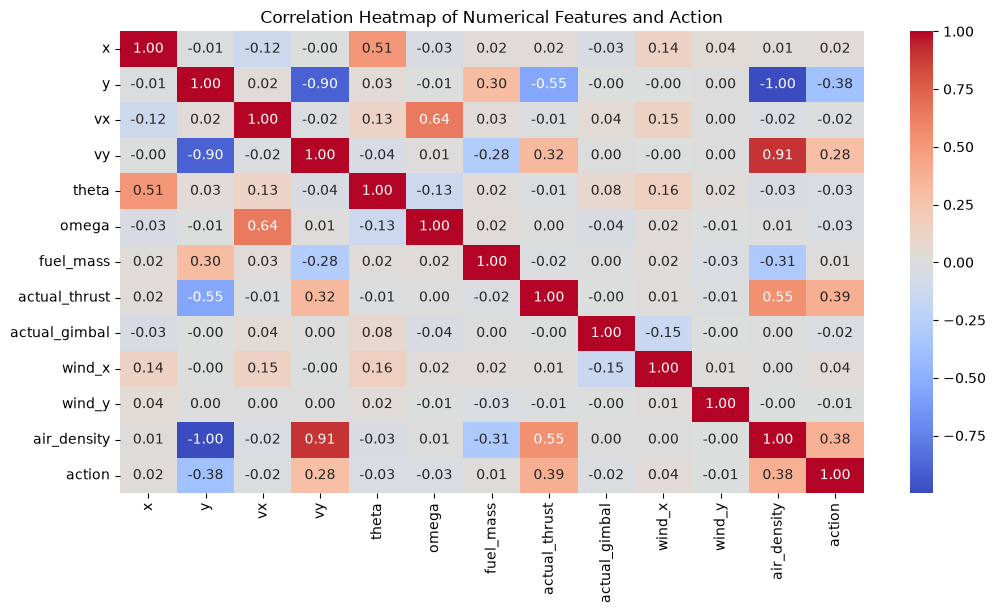

In [81]:
plt.figure(figsize=(12, 6))
y = "action"
sns.heatmap(train_landings[numerical_features + [y]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features and Action")
plt.show()

In [ ]:
controller = Controller(learning_rate=learning_rate, epochs=epochs)
train_X, train_y = train_landings[numerical_features], train_landings["action"]
val_X, val_y = val_landings[numerical_features], val_landings["action"]
controller = controller.fit(train_X, train_y, val_X, val_y)

In [84]:
controller.save(weights_path)
print(f"Model weights saved to {weights_path}")

Model weights saved to weights.npz


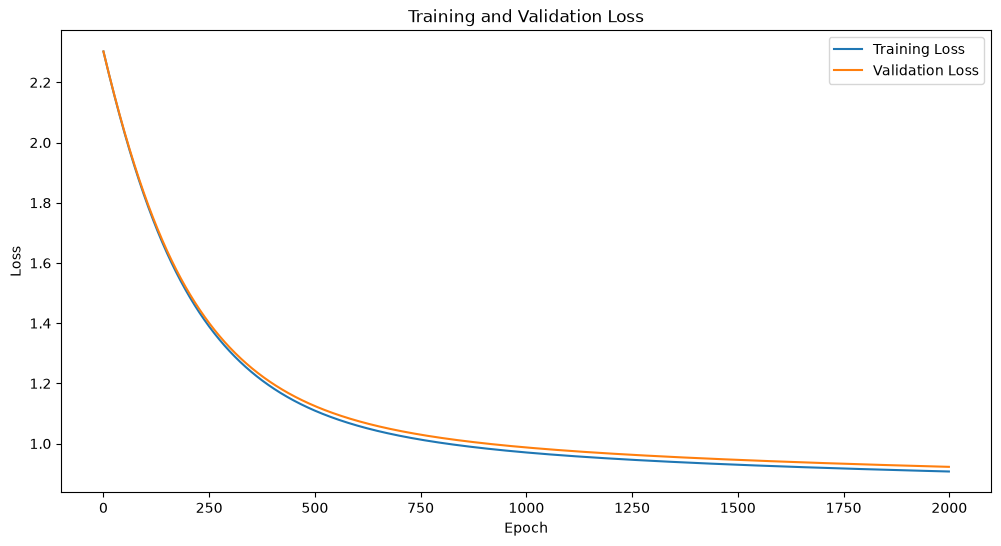

In [83]:
plt.figure(figsize=(12, 6))
plt.plot(controller.train_loss_history, label='Training Loss')
plt.plot(controller.validation_loss_history, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()